# 03 · Optimización con Optuna y comparación honesta

**Proyecto:** Alerta temprana de abandono de clientes (Telco Customer Churn)
**Curso:** Machine Learning · Maestría en Ciencia de Datos e Inteligencia Artificial · EPG UNAJ
**Docente:** Dr. Alain Paul Herrera Urtiaga
**Equipo:** Leydy Mayumy Coyllo Mamani · Noe Wilber Tipo Mamani · Jose Alfonso Nina Condori
**Práctica:** P2

> **Pregunta del proyecto:** con los datos actuales de un cliente, ¿qué clientes cancelarán su servicio?

**Objetivo de este notebook:** optimizar LightGBM con Optuna y comprobar con una prueba estadística si la mejora frente al modelo original y al mejor modelo de la P1 es real o un empate.

In [1]:
# Configuración común (ejecución local o en Google Colab)
import warnings
warnings.filterwarnings("ignore")
import importlib, subprocess, sys
for _paquete in ["lightgbm", "optuna"]:
    try:
        importlib.import_module(_paquete)
    except ImportError:  # en Colab puede faltar alguna librería
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", _paquete], check=True)

import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

SEMILLA = 42
URL_CSV = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
RUTA_LOCAL = Path("../data/Telco-Customer-Churn.csv")
EN_REPO = RUTA_LOCAL.exists()
RES = Path("../resultados") if EN_REPO else Path("resultados")
FIG = RES / "figuras"
FIG.mkdir(parents=True, exist_ok=True)

# Paleta: azul = no abandona, naranja = abandona
AZUL, NARANJA, AGUA, AMARILLO, GRIS = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#8a8984"
plt.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 150, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.titleweight": "bold",
})

def guardar_figura(fig, nombre):
    fig.savefig(FIG / nombre, dpi=150, bbox_inches="tight")

def guardar_json(obj, nombre):
    (RES / nombre).write_text(json.dumps(obj, ensure_ascii=False, indent=2), encoding="utf-8")

print("Datos locales:" if EN_REPO else "Datos desde la URL pública:", RUTA_LOCAL if EN_REPO else URL_CSV)

Datos locales: ../data/Telco-Customer-Churn.csv


In [2]:
# Carga y traducción al español (equivalente a src/churn/datos.py)
MAPEO_COLUMNAS = {
    "customerID": "id_cliente",
    "gender": "genero",
    "SeniorCitizen": "adulto_mayor",
    "Partner": "tiene_pareja",
    "Dependents": "tiene_dependientes",
    "tenure": "antiguedad_meses",
    "PhoneService": "servicio_telefonico",
    "MultipleLines": "lineas_multiples",
    "InternetService": "servicio_internet",
    "OnlineSecurity": "seguridad_en_linea",
    "OnlineBackup": "respaldo_en_linea",
    "DeviceProtection": "proteccion_dispositivo",
    "TechSupport": "soporte_tecnico",
    "StreamingTV": "tv_streaming",
    "StreamingMovies": "peliculas_streaming",
    "Contract": "tipo_contrato",
    "PaperlessBilling": "factura_electronica",
    "PaymentMethod": "metodo_pago",
    "MonthlyCharges": "cargo_mensual",
    "TotalCharges": "cargo_total",
    "Churn": "abandona",
}

MAPEO_VALORES = {
    "Yes": "Sí",
    "No": "No",
    "No internet service": "Sin internet",
    "No phone service": "Sin teléfono",
    "Month-to-month": "Mensual",
    "One year": "Un año",
    "Two year": "Dos años",
    "Fiber optic": "Fibra óptica",
    "DSL": "DSL",
    "Electronic check": "Cheque electrónico",
    "Mailed check": "Cheque por correo",
    "Bank transfer (automatic)": "Transferencia bancaria (automática)",
    "Credit card (automatic)": "Tarjeta de crédito (automática)",
    "Male": "Hombre",
    "Female": "Mujer",
}

OBJETIVO = "abandona"
ID = "id_cliente"
NUMERICAS = ["antiguedad_meses", "cargo_mensual"]
CATEGORICAS = [
    "genero", "adulto_mayor", "tiene_pareja", "tiene_dependientes",
    "servicio_telefonico", "lineas_multiples", "servicio_internet",
    "seguridad_en_linea", "respaldo_en_linea", "proteccion_dispositivo",
    "soporte_tecnico", "tv_streaming", "peliculas_streaming",
    "tipo_contrato", "factura_electronica", "metodo_pago",
]
# cargo_total se excluye por redundancia: r = 0.9996 con antigüedad × cargo mensual.
EXCLUIDAS = [ID, "cargo_total"]
VARIABLES_MODELO = NUMERICAS + CATEGORICAS


def traducir(df: pd.DataFrame) -> pd.DataFrame:
    """Renombra columnas y traduce categorías. Acepta columnas en inglés o ya en español.

    No imputa: los blancos de ``cargo_total`` quedan como NaN.
    """
    df = df.rename(columns=MAPEO_COLUMNAS).copy()
    for col in df.columns:
        if col in (ID, OBJETIVO, "cargo_total") or col in NUMERICAS:
            continue
        if col == "adulto_mayor":
            df[col] = df[col].map(
                lambda v: "Sí" if str(v).strip() in ("1", "1.0", "Sí", "Si", "Yes")
                else ("No" if str(v).strip() in ("0", "0.0", "No") else np.nan)
            )
            continue
        if df[col].dtype == object or pd.api.types.is_string_dtype(df[col]):
            df[col] = df[col].map(lambda v: MAPEO_VALORES.get(v, v) if isinstance(v, str) else v)
            if col == "servicio_internet":  # en esta columna "No" significa "sin internet"
                df[col] = df[col].replace({"No": "Sin internet"})
    if "cargo_total" in df.columns:
        df["cargo_total"] = pd.to_numeric(
            df["cargo_total"].astype(str).str.strip().replace("", np.nan), errors="coerce"
        )
    for col in NUMERICAS:
        if col in df.columns:
            df[col] = pd.to_numeric(df[col], errors="coerce")
    if OBJETIVO in df.columns and not pd.api.types.is_numeric_dtype(df[OBJETIVO]):
        df[OBJETIVO] = df[OBJETIVO].map({"Yes": 1, "No": 0, "Sí": 1}).astype(int)
    return df


def separar_X_y(df: pd.DataFrame):
    """Devuelve (X, y) con solo las variables que usa el modelo."""
    return df[VARIABLES_MODELO].copy(), df[OBJETIVO].astype(int).copy()

df_crudo = pd.read_csv(RUTA_LOCAL) if EN_REPO else pd.read_csv(URL_CSV)
df = traducir(df_crudo)
print(df.shape)

(7043, 21)


In [3]:
# Preprocesamiento dentro de un Pipeline (equivalente a src/churn/preprocesamiento.py)
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

def construir_preprocesador(numericas=None, categoricas=None) -> ColumnTransformer:
    numericas = list(NUMERICAS if numericas is None else numericas)
    categoricas = list(CATEGORICAS if categoricas is None else categoricas)
    num = Pipeline([
        ("imputar", SimpleImputer(strategy="median")),
        ("escalar", StandardScaler()),
    ])
    cat = Pipeline([
        ("imputar", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ])
    return ColumnTransformer(
        [("num", num, numericas), ("cat", cat, categoricas)],
        remainder="drop",
    )


def construir_pipeline(modelo, numericas=None, categoricas=None) -> Pipeline:
    """Pipeline completo: preprocesamiento + modelo."""
    return Pipeline([
        ("prep", construir_preprocesador(numericas, categoricas)),
        ("modelo", modelo),
    ])

In [4]:
# División 80/20 estratificada, semilla 42
from sklearn.model_selection import train_test_split
X, y = separar_X_y(df)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEMILLA)
print(f"Entrenamiento: {len(X_train)} filas · Test: {len(X_test)} filas · "
      f"abandono train {y_train.mean():.3f} / test {y_test.mean():.3f}")

Entrenamiento: 5634 filas · Test: 1409 filas · abandono train 0.265 / test 0.265


## 1. Optimización de LightGBM con Optuna

- **Búsqueda:** 40 intentos con el muestreador TPE sembrado (`seed=42`).
- **Desbalance:** `class_weight="balanced"` en todos los intentos (los errores en la clase "abandona" pesan más).
- **Función objetivo:** PR-AUC promedio en validación cruzada estratificada de 5 folds **sobre el entrenamiento** (el test no se usa). No se optimiza el recall directamente porque se puede inflar a costa de marcar a casi todos como riesgo; PR-AUC premia ordenar bien a los clientes y el recall se fija después con el umbral.

In [5]:
import optuna
from lightgbm import LGBMClassifier
from sklearn.model_selection import StratifiedKFold, RepeatedStratifiedKFold, cross_validate, cross_val_score
optuna.logging.set_verbosity(optuna.logging.WARNING)
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)

def objetivo(trial):
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 100, 800, step=50),
        "learning_rate": trial.suggest_float("learning_rate", 0.005, 0.2, log=True),
        "num_leaves": trial.suggest_int("num_leaves", 4, 64),
        "max_depth": trial.suggest_int("max_depth", 2, 10),
        "min_child_samples": trial.suggest_int("min_child_samples", 10, 150),
        "subsample": trial.suggest_float("subsample", 0.5, 1.0),
        "subsample_freq": 1,
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.3, 1.0),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 10.0, log=True),
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-3, 10.0, log=True),
    }
    modelo = LGBMClassifier(**params, class_weight="balanced", random_state=SEMILLA, n_jobs=1, verbose=-1)
    return cross_val_score(construir_pipeline(modelo), X_train, y_train, cv=cv5, scoring="average_precision").mean()

estudio = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEMILLA))
estudio.optimize(objetivo, n_trials=40)
mejores = {**estudio.best_params, "subsample_freq": 1}
intentos = estudio.trials_dataframe()[["number", "value"] + [c for c in estudio.trials_dataframe() if c.startswith("params_")]]
intentos.round(5).to_csv(RES / "03_optuna_intentos.csv", index=False)
guardar_json({"mejor_pr_auc_cv": round(estudio.best_value, 4), "mejor_intento": estudio.best_trial.number,
              "n_intentos": len(estudio.trials), "parametros": mejores}, "03_optuna_mejores.json")
print(f"Mejor PR-AUC en CV: {estudio.best_value:.4f} (intento {estudio.best_trial.number})")
mejores

Mejor PR-AUC en CV: 0.6711 (intento 30)


{'n_estimators': 600,
 'learning_rate': 0.018928663564375343,
 'num_leaves': 32,
 'max_depth': 2,
 'min_child_samples': 132,
 'subsample': 0.630050532322413,
 'colsample_bytree': 0.8722648734591396,
 'reg_lambda': 4.478210759792659,
 'reg_alpha': 0.28373105188382913,
 'subsample_freq': 1}

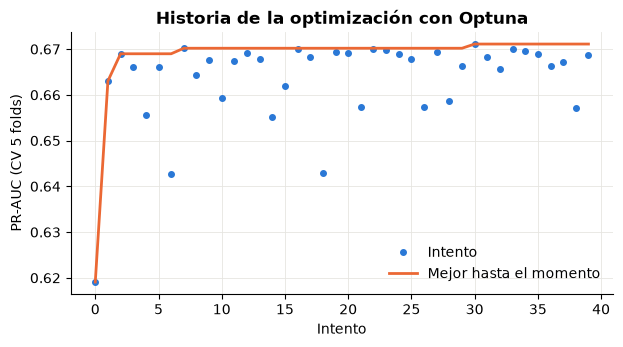

In [6]:
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.plot(intentos["number"], intentos["value"], "o", color=AZUL, ms=4, label="Intento")
ax.plot(intentos["number"], intentos["value"].cummax(), "-", color=NARANJA, lw=2, label="Mejor hasta el momento")
ax.set_title("Historia de la optimización con Optuna"); ax.set_xlabel("Intento"); ax.set_ylabel("PR-AUC (CV 5 folds)")
ax.legend(frameon=False)
guardar_figura(fig, "03_optuna_historia.png"); plt.show()

**Lectura.** El mejor intento (n.º 30) alcanza un **PR-AUC de 0.671** en validación cruzada, frente a 0.646 de LightGBM con parámetros por defecto (notebook 02). Los parámetros elegidos describen un modelo **muy regularizado**: árboles de profundidad 2, muchas observaciones por hoja (132), tasa de aprendizaje baja (0.019) con 600 árboles y submuestreo de filas y columnas. Es decir, Optuna encontró que lo que conviene aquí es un boosting "suave", cercano a un modelo aditivo, no árboles profundos. La curva de la figura se estabiliza después de unos 20 intentos.

## 2. Comparación fold a fold (5 folds × 5 repeticiones) y prueba de Wilcoxon

Comparamos, con **los mismos 25 folds** para todos:

1. LightGBM optimizado con Optuna.
2. LightGBM original (los parámetros por defecto de la P1).
3. Regresión logística L2 (el mejor modelo de la P1).

La **prueba de rangos con signo de Wilcoxon** compara las diferencias fold a fold entre dos modelos; si el valor p es menor que 0.05, la diferencia es poco probable que se deba al azar de la partición.

In [7]:
from sklearn.linear_model import LogisticRegression
from scipy.stats import wilcoxon

modelos = {
    "LightGBM optimizado": LGBMClassifier(**mejores, class_weight="balanced", random_state=SEMILLA, n_jobs=1, verbose=-1),
    "LightGBM original": LGBMClassifier(class_weight="balanced", random_state=SEMILLA, n_jobs=1, verbose=-1),
    "Regresión logística L2": LogisticRegression(C=1.0, class_weight="balanced", max_iter=2000),
}
cv_rep = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=SEMILLA)
METRICAS = {"recall": "recall", "precision": "precision", "roc_auc": "roc_auc", "pr_auc": "average_precision"}
folds = {}
for nombre, modelo in modelos.items():
    r = cross_validate(construir_pipeline(modelo), X_train, y_train, cv=cv_rep, scoring=METRICAS)
    folds[nombre] = {m: r[f"test_{m}"] for m in METRICAS}
largo = pd.concat([pd.DataFrame({"modelo": n, "fold": np.arange(1, 26), **v}) for n, v in folds.items()])
largo.round(4).to_csv(RES / "03_comparacion_folds.csv", index=False)
resumen = pd.DataFrame({n: {f"{m}_{s}": getattr(v[m], s)() for m in METRICAS for s in ("mean", "std")}
                        for n, v in folds.items()}).T.round(4)
resumen.columns = [c.replace("_mean", "_media").replace("_std", "_desv") for c in resumen.columns]
resumen.index.name = "modelo"
resumen.to_csv(RES / "03_resumen_comparacion.csv")
resumen

,recall_media,recall_desv,precision_media,precision_desv,roc_auc_media,roc_auc_desv,pr_auc_media,pr_auc_desv
modelo,,,,,,,,
LightGBM optimizado,0.8087,0.0281,0.5215,0.0155,0.8500,0.0124,0.6699,0.0186
LightGBM original,0.7359,0.0297,0.5423,0.0185,0.8372,0.0113,0.6493,0.0191
Regresión logística L2,0.7957,0.0267,0.5209,0.0141,0.8445,0.0111,0.6573,0.0164


In [8]:
pares = [("LightGBM optimizado", "LightGBM original"), ("LightGBM optimizado", "Regresión logística L2"),
         ("LightGBM original", "Regresión logística L2")]
filas = []
for a, b in pares:
    for m in METRICAS:
        d = folds[a][m] - folds[b][m]
        p = wilcoxon(folds[a][m], folds[b][m]).pvalue if np.any(d != 0) else 1.0
        filas.append({"modelo_A": a, "modelo_B": b, "metrica": m, "media_A": folds[a][m].mean(),
                      "media_B": folds[b][m].mean(), "diferencia_media": d.mean(),
                      "folds_gana_A": int((d > 0).sum()), "folds_gana_B": int((d < 0).sum()),
                      "empates": int((d == 0).sum()), "p_valor": p, "significativo_5pct": bool(p < 0.05)})
wil = pd.DataFrame(filas)
wil = wil.round({c: 4 for c in wil.columns if c != "p_valor"})  # el valor p se guarda sin redondear
wil.to_csv(RES / "03_wilcoxon.csv", index=False)
wil

,modelo_A,modelo_B,metrica,media_A,media_B,diferencia_media,folds_gana_A,folds_gana_B,empates,p_valor,significativo_5pct
0,LightGBM optimizado,LightGBM original,recall,0.8087,0.7359,0.0728,25,0,0,1.192707e-05,True
1,LightGBM optimizado,LightGBM original,precision,0.5215,0.5423,-0.0208,2,23,0,4.172325e-07,True
2,LightGBM optimizado,LightGBM original,roc_auc,0.8500,0.8372,0.0128,25,0,0,5.960464e-08,True
3,LightGBM optimizado,LightGBM original,pr_auc,0.6699,0.6493,0.0206,25,0,0,5.960464e-08,True
4,LightGBM optimizado,Regresión logística L2,recall,0.8087,0.7957,0.0130,19,5,1,1.416562e-03,True
5,LightGBM optimizado,Regresión logística L2,precision,0.5215,0.5209,0.0006,12,13,0,7.914760e-01,False
6,LightGBM optimizado,Regresión logística L2,roc_auc,0.8500,0.8445,0.0055,22,3,0,2.563000e-06,True
7,LightGBM optimizado,Regresión logística L2,pr_auc,0.6699,0.6573,0.0126,22,3,0,8.344650e-07,True
8,LightGBM original,Regresión logística L2,recall,0.7359,0.7957,-0.0598,0,25,0,1.217932e-05,True
9,LightGBM original,Regresión logística L2,precision,0.5423,0.5209,0.0214,23,2,0,8.344650e-07,True


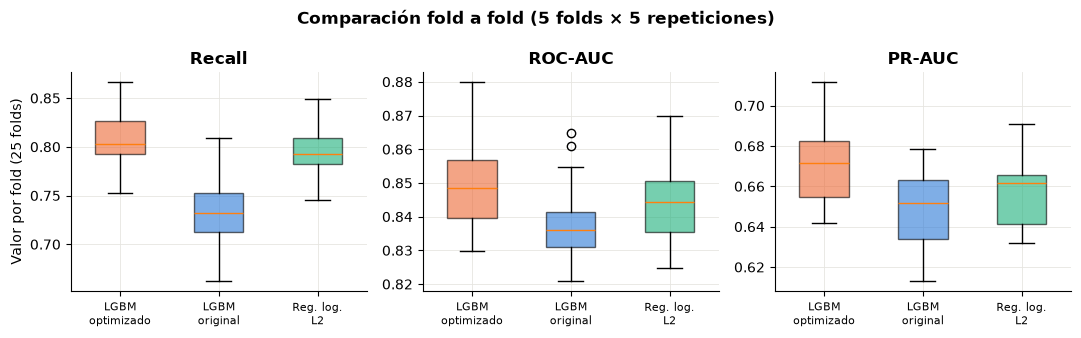

In [9]:
fig, axs = plt.subplots(1, 3, figsize=(11, 3.4))
nombres = list(modelos)
for ax, (m, etiqueta) in zip(axs, [("recall", "Recall"), ("roc_auc", "ROC-AUC"), ("pr_auc", "PR-AUC")]):
    caja = ax.boxplot([folds[n][m] for n in nombres], patch_artist=True, widths=0.5)
    for parche, color in zip(caja["boxes"], [NARANJA, AZUL, AGUA]):
        parche.set_facecolor(color); parche.set_alpha(0.6)
    ax.set_xticks([1, 2, 3]); ax.set_xticklabels(["LGBM\noptimizado", "LGBM\noriginal", "Reg. log.\nL2"], fontsize=8)
    ax.set_title(etiqueta)
axs[0].set_ylabel("Valor por fold (25 folds)")
fig.suptitle("Comparación fold a fold (5 folds × 5 repeticiones)", fontweight="bold")
fig.tight_layout()
guardar_figura(fig, "03_comparacion_folds.png"); plt.show()

**Lectura (25 folds iguales para los tres modelos).**
- **Optimizado vs. original:** el optimizado gana en recall (0.809 frente a 0.736), ROC-AUC y PR-AUC **en los 25 folds** (p < 0.0001). A cambio pierde algo de precisión (0.522 frente a 0.542). La optimización sí cambió el modelo de forma real.
- **Optimizado vs. regresión logística (mejor de la P1):** el optimizado gana en recall en **19 de 25 folds** (+0.013 en promedio, p = 0.0014), en ROC-AUC en 22 de 25 (+0.006) y en PR-AUC en 22 de 25 (+0.013); en precisión empatan (p = 0.79).
- **Cautela:** la mejora frente a la regresión logística es **estadísticamente significativa pero pequeña** (poco más de un punto de recall). Además, los 25 folds comparten datos entre sí y Optuna se ajustó con estos mismos datos de entrenamiento, así que el valor p es algo optimista.

## 3. Umbral de decisión

Con `class_weight="balanced"` el umbral por defecto de 0.5 ya favorece a la clase minoritaria. Revisamos cómo cambian recall y precisión al mover el umbral usando predicciones *fuera de fold* del entrenamiento (sin tocar el test).

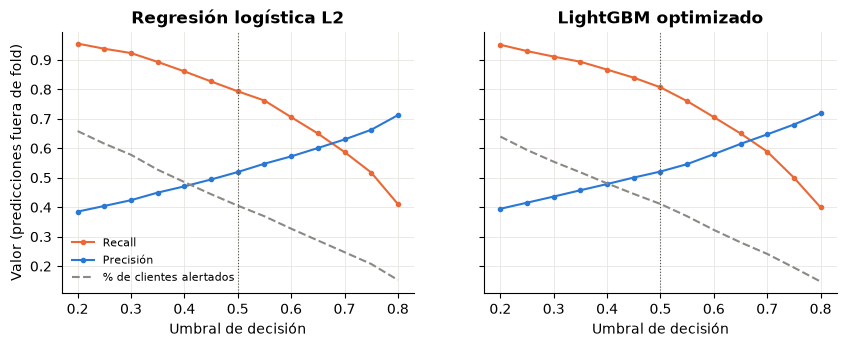

,modelo,umbral,recall,precision,porc_alertas
2,Regresión logística L2,0.3,0.9231,0.4238,0.5779
4,Regresión logística L2,0.4,0.8609,0.4707,0.4853
6,Regresión logística L2,0.5,0.7933,0.5193,0.4054
8,Regresión logística L2,0.6,0.7057,0.5724,0.3271
15,LightGBM optimizado,0.3,0.9110,0.4361,0.5543
17,LightGBM optimizado,0.4,0.8669,0.4786,0.4807
19,LightGBM optimizado,0.5,0.8067,0.5210,0.4109
21,LightGBM optimizado,0.6,0.7057,0.5800,0.3229


In [10]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_score, recall_score
umbrales = np.round(np.arange(0.20, 0.81, 0.05), 2)
filas = []
for nombre in ["Regresión logística L2", "LightGBM optimizado"]:
    prob_oof = cross_val_predict(construir_pipeline(modelos[nombre]), X_train, y_train, cv=cv5, method="predict_proba")[:, 1]
    for u in umbrales:
        pred = (prob_oof >= u).astype(int)
        filas.append({"modelo": nombre, "umbral": u, "recall": recall_score(y_train, pred),
                      "precision": precision_score(y_train, pred), "porc_alertas": pred.mean()})
tabla_umbral = pd.DataFrame(filas).round(4)
tabla_umbral.to_csv(RES / "03_umbral.csv", index=False)

fig, axs = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
for ax, nombre in zip(axs, ["Regresión logística L2", "LightGBM optimizado"]):
    t = tabla_umbral[tabla_umbral.modelo == nombre]
    ax.plot(t["umbral"], t["recall"], "-o", color=NARANJA, ms=3, label="Recall")
    ax.plot(t["umbral"], t["precision"], "-o", color=AZUL, ms=3, label="Precisión")
    ax.plot(t["umbral"], t["porc_alertas"], "--", color=GRIS, label="% de clientes alertados")
    ax.axvline(0.5, color="#52514e", lw=0.8, ls=":")
    ax.set_title(nombre); ax.set_xlabel("Umbral de decisión")
axs[0].set_ylabel("Valor (predicciones fuera de fold)"); axs[0].legend(frameon=False, fontsize=8)
guardar_figura(fig, "03_umbral.png"); plt.show()
tabla_umbral[tabla_umbral.umbral.isin([0.3, 0.4, 0.5, 0.6])]

**Lectura.** Bajar el umbral sube el recall a costa de la precisión y de alertar a más clientes: para LightGBM optimizado, con umbral 0.3 el recall llega a 0.911 pero se alerta al 55 % de los clientes; con 0.5 el recall es 0.807 alertando al 41 %. **Mantenemos el umbral 0.5**: con `class_weight="balanced"` ya favorece el recall, y elegir otro umbral depende del presupuesto de retención de la empresa (cuántos clientes puede contactar), un dato que no tenemos. La tabla queda como guía para esa decisión.

## 4. Decisión

Regla: el modelo optimizado solo reemplaza al mejor de la P1 si **gana en recall (la métrica principal) con p < 0.05** y no pierde de forma significativa en PR-AUC. Si no, es un empate y se elige el **más simple** (la regresión logística).

In [11]:
w = wil.set_index(["modelo_A", "modelo_B", "metrica"])
opt_vs_log = w.loc[("LightGBM optimizado", "Regresión logística L2")]
gana_recall = opt_vs_log.loc["recall", "diferencia_media"] > 0 and opt_vs_log.loc["recall", "significativo_5pct"]
pierde_pr = opt_vs_log.loc["pr_auc", "diferencia_media"] < 0 and opt_vs_log.loc["pr_auc", "significativo_5pct"]
if gana_recall and not pierde_pr:
    seleccion = {"modelo": "LightGBM optimizado", "clase": "LGBMClassifier",
                 "parametros": {**mejores, "class_weight": "balanced", "random_state": SEMILLA, "n_jobs": 1, "verbose": -1}}
else:
    seleccion = {"modelo": "Regresión logística L2", "clase": "LogisticRegression",
                 "parametros": {"C": 1.0, "class_weight": "balanced", "max_iter": 2000}}
seleccion["umbral"] = 0.5
seleccion["razon"] = ("El modelo optimizado gana en recall con p < 0.05." if gana_recall and not pierde_pr else
                      "El modelo optimizado no supera a la regresión logística en recall con p < 0.05: "
                      "se elige el modelo más simple.")
guardar_json(seleccion, "03_seleccion.json")
seleccion

{'modelo': 'LightGBM optimizado',
 'clase': 'LGBMClassifier',
 'parametros': {'n_estimators': 600,
  'learning_rate': 0.018928663564375343,
  'num_leaves': 32,
  'max_depth': 2,
  'min_child_samples': 132,
  'subsample': 0.630050532322413,
  'colsample_bytree': 0.8722648734591396,
  'reg_lambda': 4.478210759792659,
  'reg_alpha': 0.28373105188382913,
  'subsample_freq': 1,
  'class_weight': 'balanced',
  'random_state': 42,
  'n_jobs': 1,
  'verbose': -1},
 'umbral': 0.5,
 'razon': 'El modelo optimizado gana en recall con p < 0.05.'}

## Conclusiones

1. **Optuna mejoró a LightGBM de forma real** frente a su versión por defecto: más recall (0.809 frente a 0.736), ROC-AUC y PR-AUC en los 25 folds.
2. **Frente a la regresión logística, la mejora es pequeña pero consistente**: +0.013 de recall (19 de 25 folds, p = 0.0014), y también gana en ROC-AUC y PR-AUC. Según la regla fijada de antemano, **el modelo final es LightGBM optimizado**.
3. Siendo honestos: la diferencia práctica es modesta y la regresión logística sigue siendo una alternativa razonable si se prioriza la simplicidad; la elegiríamos si la prueba no hubiera sido significativa.
4. Se mantiene el umbral 0.5; la tabla de umbrales permite ajustarlo según el presupuesto de retención.